# Data Science Challenge Hackathon 2026

## Section 1: Introduction

This project aims to predict seasonal influenza vaccination uptake using machine learning.

The objective is to develop and compare predictive models while considering the financial costs of vaccination and hospitalisation.

**Target Variable:** seasonal_vaccine

**Dataset:** Dataset A

**Approach:** Exploratory Data Analysis, Data Preprocessing, Machine Learning, Model Evaluation and Cost Analysis.

## IMPORTING REQUIRED LIBRARIES

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

print("Libraries imported successfully!")

Libraries imported successfully!


## UPLOADING REQUIRED DATASETS

In [33]:
from google.colab import files

uploaded = files.upload()

Saving dataset_A_example_submission.csv to dataset_A_example_submission.csv
Saving dataset_A_testing.csv to dataset_A_testing (1).csv
Saving dataset_A_training.csv to dataset_A_training (1).csv


In [34]:
train_df = pd.read_csv("dataset_A_training.csv")
test_df = pd.read_csv("dataset_A_testing.csv")

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

display(train_df.head())

Training dataset: (4756, 31)
Testing dataset: (4749, 30)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


## DATASET EXPLORATION

In [35]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("\nTraining Dataset Information:")
train_df.info()

Training Dataset Shape: (4756, 31)
Testing Dataset Shape: (4749, 30)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   flu_concern                    4744 non-null   float64
 2   flu_knowledge                  4733 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4724 non-null   float64
 5   behavioral_face_mask           4753 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4747 non-null   float64
 9   behavioral_touch_face          4737 non-null   float64
 10  doctor_recc_seasonal           4435 non-null   float64
 11  child_un

In [36]:
print("Missing Values in Training Dataset:")
display(train_df.isnull().sum())

print("\nMissing Values in Testing Dataset:")
display(test_df.isnull().sum())

Missing Values in Training Dataset:


,0
respondent_id,0
flu_concern,12
flu_knowledge,23
behavioral_antiviral_meds,14
behavioral_avoidance,32
behavioral_face_mask,3
behavioral_wash_hands,8
behavioral_large_gatherings,9
behavioral_outside_home,9
behavioral_touch_face,19



Missing Values in Testing Dataset:


,0
respondent_id,0
flu_concern,21
flu_knowledge,18
behavioral_antiviral_meds,14
behavioral_avoidance,47
behavioral_face_mask,3
behavioral_wash_hands,6
behavioral_large_gatherings,27
behavioral_outside_home,12
behavioral_touch_face,30


In [37]:
print("Duplicate Rows in Training:", train_df.duplicated().sum())
print("Duplicate Rows in Testing:", test_df.duplicated().sum())

Duplicate Rows in Training: 0
Duplicate Rows in Testing: 0


Seasonal Vaccine Distribution:
seasonal_vaccine
1    2551
0    2205
Name: count, dtype: int64


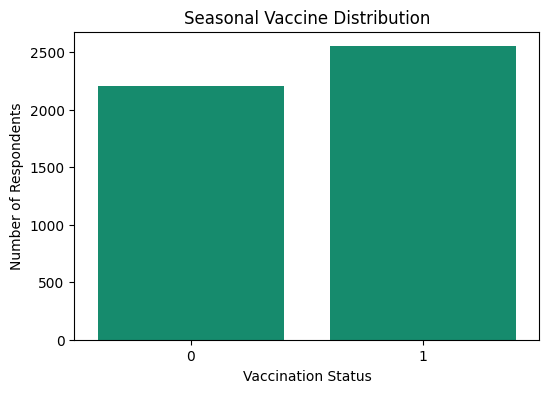

In [38]:
print("Seasonal Vaccine Distribution:")
print(train_df["seasonal_vaccine"].value_counts())

plt.figure(figsize=(6, 4))

sns.countplot(
    data=train_df,
    x="seasonal_vaccine", color="#029f76"
)

plt.title("Seasonal Vaccine Distribution")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.show()

In [39]:
display(train_df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
flu_concern,4744.0,NaN,NaN,NaN,1.643128,0.91981,0.0,1.0,2.0,2.0,3.0
flu_knowledge,4733.0,NaN,NaN,NaN,1.293049,0.618902,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.052299,0.222652,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,NaN,NaN,NaN,0.734124,0.441846,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,NaN,NaN,NaN,0.073848,0.261551,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.836563,0.369803,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.365494,0.481619,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,NaN,NaN,NaN,0.336634,0.472608,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,NaN,NaN,NaN,0.68841,0.463192,0.0,0.0,1.0,1.0,1.0


## Dataset Exploration

The training and testing datasets were examined to understand
their structure, data types, missing values, and duplicate records.

The distribution of the target variable, seasonal_vaccine,
was analysed to identify potential class imbalance.

Summary statistics were also generated to understand the
characteristics of the dataset.

These findings will guide the preprocessing and machine
learning stages.

## EXPLORATORY DATA ANALYSIS (EDA)

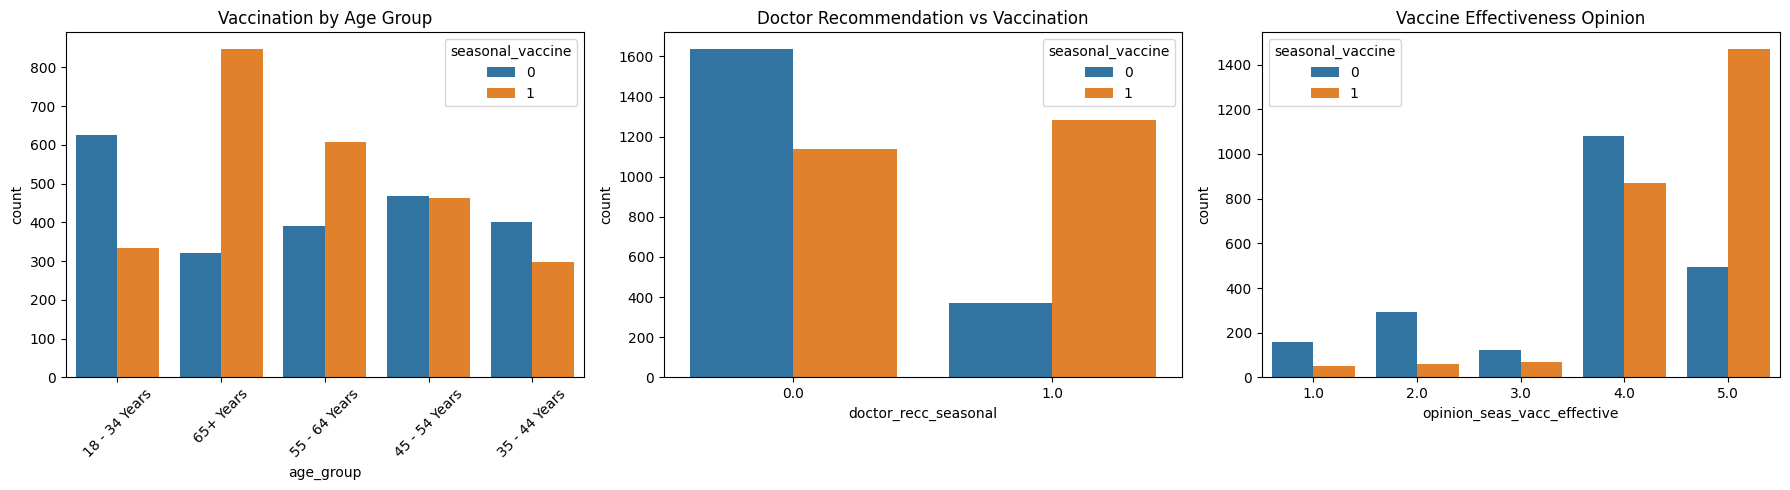

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Vaccination by Age Group
sns.countplot(
    data=train_df,
    x="age_group",
    hue="seasonal_vaccine",
    ax=axes[0]
)
axes[0].set_title("Vaccination by Age Group")
axes[0].tick_params(axis="x", rotation=45)

# Plot 2: Doctor Recommendation and Vaccination
sns.countplot(
    data=train_df,
    x="doctor_recc_seasonal",
    hue="seasonal_vaccine",
    ax=axes[1]
)
axes[1].set_title("Doctor Recommendation vs Vaccination")

# Plot 3: Vaccine Effectiveness Opinion
sns.countplot(
    data=train_df,
    x="opinion_seas_vacc_effective",
    hue="seasonal_vaccine",
    ax=axes[2]
)
axes[2].set_title("Vaccine Effectiveness Opinion")

plt.tight_layout()
plt.show()

In [41]:
features = [
    "age_group",
    "doctor_recc_seasonal",
    "opinion_seas_vacc_effective"
]

for feature in features:
    print(f"\nVaccination Rate by {feature}:")

    display(
        train_df.groupby(feature)["seasonal_vaccine"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "vaccination_rate"})
    )


Vaccination Rate by age_group:


,count,vaccination_rate
age_group,,
18 - 34 Years,960,0.348958
35 - 44 Years,697,0.426112
45 - 54 Years,931,0.497315
55 - 64 Years,999,0.608609
65+ Years,1169,0.725406



Vaccination Rate by doctor_recc_seasonal:


,count,vaccination_rate
doctor_recc_seasonal,,
0.0,2778,0.410367
1.0,1657,0.775498



Vaccination Rate by opinion_seas_vacc_effective:


,count,vaccination_rate
opinion_seas_vacc_effective,,
1.0,209,0.244019
2.0,351,0.168091
3.0,191,0.356021
4.0,1948,0.445585
5.0,1963,0.749363


## Exploratory Data Analysis

Three visualisations were created to investigate the relationship between seasonal vaccination and selected respondent characteristics.

1. **Age Group:** Examines how vaccination uptake differs across age categories.
2. **Doctor Recommendation:** Investigates whether receiving a doctor's recommendation is associated with vaccination uptake.
3. **Vaccine Effectiveness Opinion:** Explores the relationship between respondents' perceptions of vaccine effectiveness and vaccination decisions.

Vaccination rates were also calculated for each category to support the graphical analysis.

These findings will help identify potentially useful predictors for machine learning. The observed relationships are associations and do not necessarily indicate causation.

## DATA PREPROCESSING

In [42]:
# Separate features and target

X = train_df.drop(
    columns=["respondent_id", "seasonal_vaccine"]
)

y = train_df["seasonal_vaccine"]

# Prepare testing dataset
X_test = test_df.drop(columns=["respondent_id"])

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Testing Shape:", X_test.shape)

Features Shape: (4756, 29)
Target Shape: (4756,)
Testing Shape: (4749, 29)


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)

Training Shape: (3804, 29)
Validation Shape: (952, 29)


In [44]:
# Identify feature types

numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", len(numerical_cols))
print("Categorical Features:", len(categorical_cols))

Numerical Features: 19
Categorical Features: 10


In [45]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [46]:
print("Training Features:", X_train.shape[1])
print("Testing Features:", X_test.shape[1])

print(
    "Columns Match:",
    list(X_train.columns) == list(X_test.columns)
)

print("Missing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Testing:", X_test.isnull().sum().sum())

Training Features: 29
Testing Features: 29
Columns Match: True
Missing Values in Training: 5946
Missing Values in Testing: 7604


## Data Preprocessing

The dataset was prepared for machine learning by separating the input features from the target variable, `seasonal_vaccine`.

The `respondent_id` column was excluded because it is a unique random identifier.

The labelled dataset was divided into 80% training data and 20% validation data using stratified sampling.

Missing numerical values were handled using median imputation, while missing categorical values were handled using the most frequent category.

Categorical variables were converted using one-hot encoding, and numerical features were standardised.

A preprocessing pipeline was created to ensure consistent transformations and reduce the risk of data leakage during model training.

## ML MODEL DEVELOPMENT

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Define five machine learning models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        random_state=42
    )
}

# Store trained models and results
trained_models = {}
results = []

# Train and evaluate models
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1 Score": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

    trained_models[name] = pipeline

    print(name, "training completed!")

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

display(results_df.round(4))

Logistic Regression training completed!
Random Forest training completed!
Gradient Boosting training completed!
Extra Trees training completed!
HistGradientBoosting training completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.7815,0.7942,0.8004,0.7973,0.8534
0,Logistic Regression,0.7847,0.8024,0.7945,0.7984,0.8480
4,HistGradientBoosting,0.7794,0.7911,0.8004,0.7957,0.8450
1,Random Forest,0.7647,0.7754,0.7906,0.7829,0.8377
3,Extra Trees,0.7574,0.7789,0.7652,0.7720,0.8244


In [48]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model by ROC-AUC:", best_model_name)

print(
    "ROC-AUC Score:",
    round(results_df.iloc[0]["ROC-AUC"], 4)
)

Best Model by ROC-AUC: Gradient Boosting
ROC-AUC Score: 0.8534


## Machine Learning Model Development

Five machine learning algorithms were implemented to predict seasonal influenza vaccination uptake.

The models included Logistic Regression, Random Forest, Gradient Boosting, Extra Trees and HistGradientBoosting.

Each model was trained using the same training dataset and preprocessing pipeline to support a consistent comparison.

Model performance was evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

ROC-AUC was used for an initial comparison of the models' ability to distinguish between vaccinated and unvaccinated respondents.

However, the final model selection will also consider the financial objective of the hackathon, which is to minimise estimated vaccination and hospitalisation costs.

## MODEL PERFORMANCE ANALYSIS

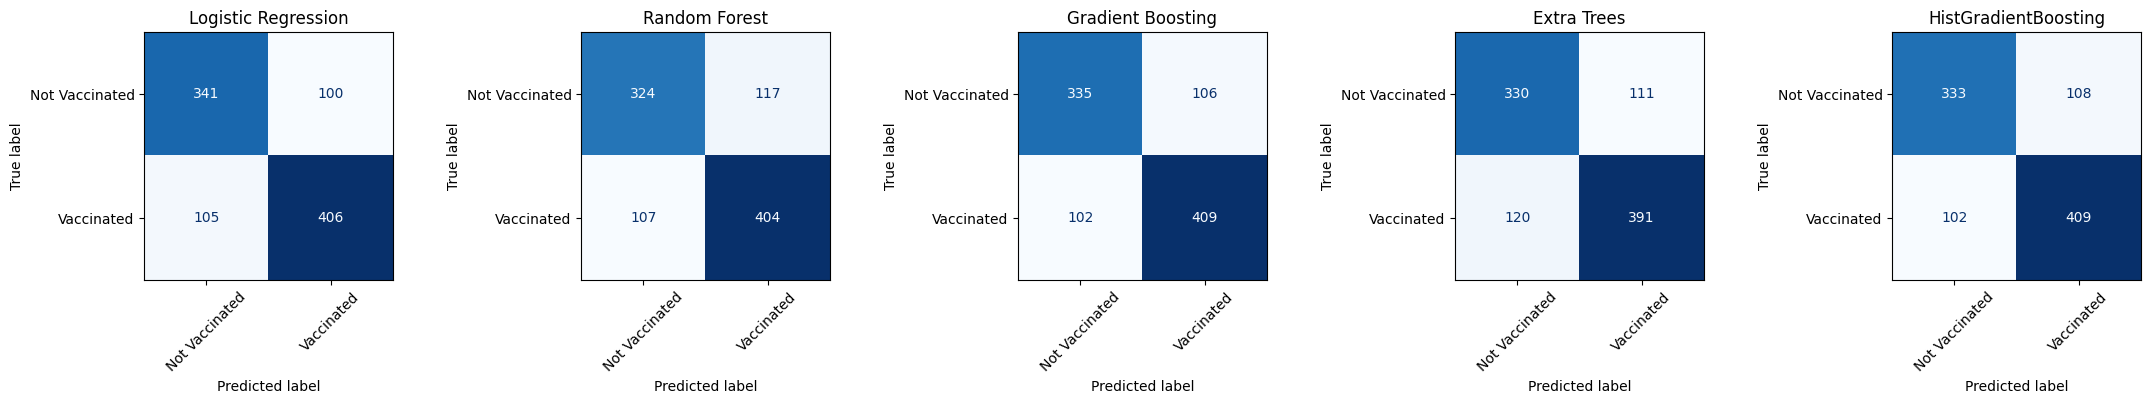

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_val)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Vaccinated", "Vaccinated"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [50]:
# Display model comparison table

comparison_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("Machine Learning Model Performance Comparison")

display(comparison_df.round(4))

Machine Learning Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Gradient Boosting,0.7815,0.7942,0.8004,0.7973,0.8534
0,Logistic Regression,0.7847,0.8024,0.7945,0.7984,0.8480
4,HistGradientBoosting,0.7794,0.7911,0.8004,0.7957,0.8450
1,Random Forest,0.7647,0.7754,0.7906,0.7829,0.8377
3,Extra Trees,0.7574,0.7789,0.7652,0.7720,0.8244


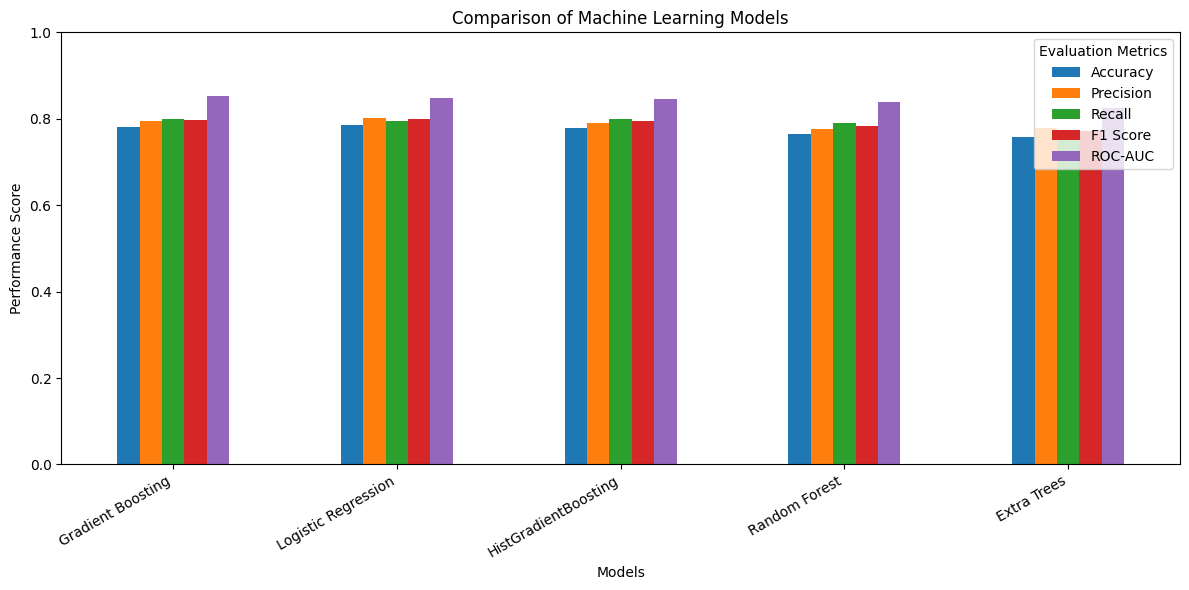

In [51]:
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Performance Score")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Evaluation Metrics")

plt.tight_layout()
plt.show()

In [52]:
best_model_row = comparison_df.iloc[0]

print("Best Model by ROC-AUC:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("Precision:", round(best_model_row["Precision"], 4))
print("Recall:", round(best_model_row["Recall"], 4))
print("F1 Score:", round(best_model_row["F1 Score"], 4))
print("ROC-AUC:", round(best_model_row["ROC-AUC"], 4))

Best Model by ROC-AUC: Gradient Boosting
Accuracy: 0.7815
Precision: 0.7942
Recall: 0.8004
F1 Score: 0.7973
ROC-AUC: 0.8534


## Model Performance Analysis

The five machine learning models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

Confusion matrices were generated to examine correct and incorrect vaccination predictions.

The comparison allows us to assess differences in model performance and identify potential trade-offs between precision and recall.

False-positive predictions may result in unnecessary vaccine expenditure, while false-negative predictions may lead to missed vaccination opportunities.

ROC-AUC was used to compare the models' classification performance independently of a single decision threshold.

However, classification performance alone does not fully address the hackathon objective. The final ranking will therefore consider estimated vaccination and hospitalisation costs.

The financial evaluation will use the specified costs of $300 per vaccine and $18,500 per hospitalisation, together with explicitly stated assumptions about hospitalisation probabilities.

## FINANCIAL COST ANALYSIS

### Defining cost

In [53]:
# Costs provided

VACCINE_COST = 300
HOSPITAL_COST = 18500

print("Vaccine Cost: $", VACCINE_COST)
print("Hospitalisation Cost: $", HOSPITAL_COST)

Vaccine Cost: $ 300
Hospitalisation Cost: $ 18500


### Estimating hospital probabilities

In [54]:
import numpy as np
import pandas as pd

def estimate_hospitalisation_risk(data, vaccinated):

    # Simplified risk grouping
    age_risk = (
        data["age_group"]
        .astype(str)
        .str.contains("65+", regex=False, na=False)
    )

    chronic_risk = (
        pd.to_numeric(
            data["number_chronic_med_conditions"],
            errors="coerce"
        ).fillna(0) > 0
    )

    high_risk = age_risk | chronic_risk

    risk = np.where(
        high_risk,
        np.where(vaccinated == 1, 0.03, 0.10),
        np.where(vaccinated == 1, 0.01, 0.03)
    )

    return risk

In [55]:
def calculate_total_cost(data, predictions):

    predictions = np.asarray(predictions).astype(int)

    # Vaccination expenditure
    vaccination_cost = predictions.sum() * VACCINE_COST

    # Estimated hospitalisation probabilities
    hospital_risk = estimate_hospitalisation_risk(
        data,
        predictions
    )

    # Expected hospitalisation expenditure
    hospitalisation_cost = (
        hospital_risk.sum() * HOSPITAL_COST
    )

    total_cost = vaccination_cost + hospitalisation_cost

    return vaccination_cost, hospitalisation_cost, total_cost

In [56]:
financial_results = []

for name, model in trained_models.items():

    predictions = model.predict(X_val)

    actual = np.asarray(y_val).astype(int)
    predicted = np.asarray(predictions).astype(int)

    # Vaccines sent to predicted acceptors
    vaccine_cost = predicted.sum() * VACCINE_COST

    # Compensation for willing people not supplied
    compensation_cost = (
        ((actual == 1) & (predicted == 0)).sum()
        * VACCINE_COST
    )

    # Actual vaccination under the assumed policy
    vaccinated = (
        (actual == 1) & (predicted == 1)
    ).astype(int)

    hospital_risk = estimate_hospitalisation_risk(
        X_val,
        vaccinated
    )

    hospital_cost = hospital_risk.sum() * HOSPITAL_COST

    total_cost = (
        vaccine_cost
        + compensation_cost
        + hospital_cost
    )

    financial_results.append({
        "Model": name,
        "Vaccine Cost": vaccine_cost,
        "Compensation Cost": compensation_cost,
        "Hospitalisation Cost": hospital_cost,
        "Total Cost": total_cost
    })

financial_df = pd.DataFrame(financial_results)

financial_df = financial_df.sort_values(
    by="Total Cost",
    ascending=True
).reset_index(drop=True)

display(financial_df.round(2))

,Model,Vaccine Cost,Compensation Cost,Hospitalisation Cost,Total Cost
0,Logistic Regression,151800,31500,689310.0,872610.0
1,Gradient Boosting,154500,30600,688200.0,873300.0
2,HistGradientBoosting,155100,30600,690050.0,875750.0
3,Random Forest,156300,32100,690050.0,878450.0
4,Extra Trees,150600,36000,702260.0,888860.0


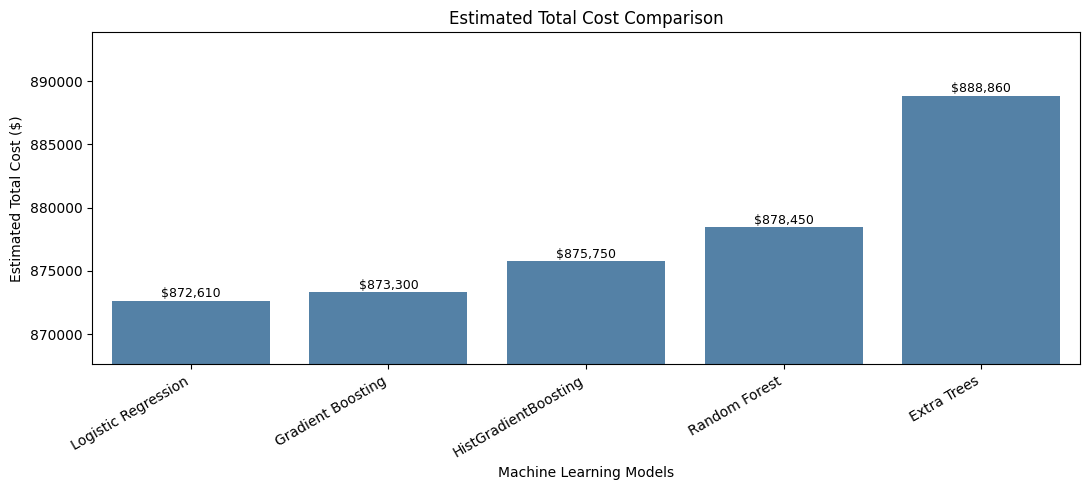

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=financial_df,
    x="Model",
    y="Total Cost",
    color="steelblue"
)

# Add exact cost values
for i, value in enumerate(financial_df["Total Cost"]):
    ax.text(
        i,
        value + 300,
        f"${value:,.0f}",
        ha="center",
        fontsize=9
    )

# Zoom in to highlight differences
minimum = financial_df["Total Cost"].min()
maximum = financial_df["Total Cost"].max()

plt.ylim(minimum - 5000, maximum + 5000)

plt.title("Estimated Total Cost Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Estimated Total Cost ($)")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [58]:
best_financial_model = financial_df.iloc[0]

print("Best Model:", best_financial_model["Model"])

print(
    "Lowest Estimated Total Cost: $",
    round(best_financial_model["Total Cost"], 2)
)

Best Model: Logistic Regression
Lowest Estimated Total Cost: $ 872610.0


## Financial Cost Analysis

The financial analysis aimed to identify the machine learning model that minimised estimated vaccination and hospitalisation expenditure.

The assignment specified a vaccination cost of $300 per person and a hospitalisation cost of $18,500 per person.

Because the dataset did not contain hospitalisation outcomes, illustrative probabilities were assigned based on age, chronic medical conditions and vaccination status.

The analysis also considered the financial consequences of incorrect vaccination acceptance predictions, including wasted vaccines and compensation for willing respondents who were not supplied.

The five models were compared using their estimated total expenditure on the validation dataset.

The model producing the lowest estimated cost was identified as the preferred model under the stated assumptions.

These findings are scenario-based rather than observed healthcare outcomes. Different hospitalisation probabilities or vaccination policies could change the model rankings.

## Generate Five Prediction CSV Files

In [59]:
GROUP_NUMBER = "E"

print("Hackathon Group:", GROUP_NUMBER)

Hackathon Group: E


In [60]:
# Rank models by estimated total cost (lowest first)

ranked_models = financial_df.sort_values(
    by="Total Cost",
    ascending=True
).reset_index(drop=True)

ranked_models["Rank"] = range(1, len(ranked_models) + 1)

display(
    ranked_models[
        ["Rank", "Model", "Total Cost"]
    ]
)

,Rank,Model,Total Cost
0,1,Logistic Regression,872610.0
1,2,Gradient Boosting,873300.0
2,3,HistGradientBoosting,875750.0
3,4,Random Forest,878450.0
4,5,Extra Trees,888860.0


In [61]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
import pandas as pd
import os

# Create folder for submission files
os.makedirs("hackathon_submissions", exist_ok=True)

submission_files = []

# Check test features match training features
assert list(X.columns) == list(X_test.columns), \
    "Training and testing columns do not match!"

for index, row in ranked_models.iterrows():

    model_name = row["Model"]
    rank = index + 1

    # Create a fresh pipeline
    final_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(models[model_name]))
    ])

    # Train using all labelled training data
    final_pipeline.fit(X, y)

    # Predict testing dataset
    predictions = final_pipeline.predict(X_test)

    # Create submission DataFrame
    submission = pd.DataFrame({
        "respondent_id": test_df["respondent_id"],
        "seasonal_vaccine": predictions.astype(int)
    })

    # Create filename
    filename = (
        f"challenge_submission_group_{GROUP_NUMBER}"
        f"_order_{rank}.csv"
    )

    filepath = os.path.join(
        "hackathon_submissions",
        filename
    )

    # Save CSV
    submission.to_csv(filepath, index=False)

    submission_files.append(filepath)

    print(f"Rank {rank}: {model_name}")
    print(f"Saved: {filename}")
    print()

Rank 1: Logistic Regression
Saved: challenge_submission_group_E_order_1.csv

Rank 2: Gradient Boosting
Saved: challenge_submission_group_E_order_2.csv

Rank 3: HistGradientBoosting
Saved: challenge_submission_group_E_order_3.csv

Rank 4: Random Forest
Saved: challenge_submission_group_E_order_4.csv

Rank 5: Extra Trees
Saved: challenge_submission_group_E_order_5.csv



In [62]:
# Validate all submission files

example = pd.read_csv(
    "dataset_A_example_submission.csv"
)

for filepath in submission_files:

    submission = pd.read_csv(filepath)

    assert submission.shape == example.shape, \
        "Incorrect submission shape!"

    assert list(submission.columns) == list(example.columns), \
        "Incorrect column names!"

    assert submission["respondent_id"].equals(
        example["respondent_id"]
    ), "Respondent IDs do not match!"

    assert submission["seasonal_vaccine"].isin(
        [0, 1]
    ).all(), "Invalid predictions!"

    assert submission["seasonal_vaccine"].notna().all(), \
        "Missing predictions!"

    print("Validated:", os.path.basename(filepath))

print("\nAll five submission files validated successfully!")

Validated: challenge_submission_group_E_order_1.csv
Validated: challenge_submission_group_E_order_2.csv
Validated: challenge_submission_group_E_order_3.csv
Validated: challenge_submission_group_E_order_4.csv
Validated: challenge_submission_group_E_order_5.csv

All five submission files validated successfully!


In [63]:
from google.colab import files
import shutil

# Create ZIP containing all five CSV files
shutil.make_archive(
    "hackathon_submissions",
    "zip",
    "hackathon_submissions"
)

# Download ZIP
files.download("hackathon_submissions.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Predictions and Submission

Five machine learning models were selected and ranked according to their estimated total financial cost on the validation dataset.

The models were retrained using the complete labelled training dataset before generating predictions for the unseen testing dataset.

Each model produced a separate CSV file containing respondent identifiers and predicted seasonal vaccination status.

The submission files were validated against the provided example submission to ensure the correct number of rows, column names, respondent identifiers and binary prediction values.

The five files were named and ordered according to the hackathon submission requirements.

The financial ranking is based on the hospitalisation-risk assumptions documented in Section 7 and should be interpreted as a scenario-based comparison.

## CRITICAL ANALYSIS AND CONCLUSIONS

In [64]:
# Combine model performance and financial results

final_results = results_df.merge(
    financial_df[
        ["Model", "Total Cost"]
    ],
    on="Model"
)

# Rank models by estimated cost
final_results = final_results.sort_values(
    by="Total Cost",
    ascending=True
).reset_index(drop=True)

final_results.insert(
    0,
    "Rank",
    range(1, len(final_results) + 1)
)

print("GROUP E - FINAL MODEL COMPARISON")

display(final_results.round(4))

GROUP E - FINAL MODEL COMPARISON


,Rank,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Total Cost
0,1,Logistic Regression,0.7847,0.8024,0.7945,0.7984,0.8480,872610.0
1,2,Gradient Boosting,0.7815,0.7942,0.8004,0.7973,0.8534,873300.0
2,3,HistGradientBoosting,0.7794,0.7911,0.8004,0.7957,0.8450,875750.0
3,4,Random Forest,0.7647,0.7754,0.7906,0.7829,0.8377,878450.0
4,5,Extra Trees,0.7574,0.7789,0.7652,0.7720,0.8244,888860.0


In [65]:
# Display final results

best = final_results.iloc[0]

print("GROUP E - HACKATHON RESULTS")
print("-----------------------------")

print("Best Model:", best["Model"])
print("Accuracy:", round(best["Accuracy"], 4))
print("Precision:", round(best["Precision"], 4))
print("Recall:", round(best["Recall"], 4))
print("F1 Score:", round(best["F1 Score"], 4))
print("ROC-AUC:", round(best["ROC-AUC"], 4))

print(
    "Estimated Total Cost: $",
    round(best["Total Cost"], 2)
)

print("\nTotal Models Compared:", len(final_results))

GROUP E - HACKATHON RESULTS
-----------------------------
Best Model: Logistic Regression
Accuracy: 0.7847
Precision: 0.8024
Recall: 0.7945
F1 Score: 0.7984
ROC-AUC: 0.848
Estimated Total Cost: $ 872610.0

Total Models Compared: 5


## Critical Analysis and Conclusions

### Model Performance

Five machine learning models were developed to predict seasonal influenza vaccination uptake: Logistic Regression, Random Forest, Gradient Boosting, Extra Trees and HistGradientBoosting.

The models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC.

Different algorithms were compared to investigate whether more complex models improved prediction performance.

### Financial Analysis

The primary objective of the challenge was to minimise vaccination and hospitalisation expenditure.

The analysis considered a vaccination cost of $300 and a hospitalisation cost of $18,500 per person.

Under the illustrative hospitalisation-risk assumptions, Logistic Regression achieved the lowest estimated total cost of $872,610.

The estimated costs of the five models were relatively similar, suggesting that more complex models did not necessarily provide better financial outcomes in this scenario.

### Critical Evaluation

Logistic Regression provides a relatively simple and interpretable approach, whereas ensemble models can capture more complex relationships between respondent characteristics and vaccination behaviour.

However, greater model complexity does not guarantee improved performance.

The financial results depend on assumed hospitalisation probabilities because the dataset does not contain observed hospitalisation outcomes.

Consequently, the estimated expenditure should be interpreted as a scenario-based comparison rather than a validated prediction of actual healthcare costs.

Further analysis should investigate alternative hospitalisation probabilities and assess whether model rankings remain consistent.

### Limitations

The main limitations include the relatively small labelled training dataset, missing values, uncertainty in hospitalisation-risk estimates and possible differences between validation performance and unseen test performance.

The analysis also uses a simplified representation of vaccine allocation and does not directly estimate individual treatment effects.

### Conclusion

Five machine learning models were successfully developed and compared for seasonal vaccination prediction.

Logistic Regression produced the lowest estimated financial cost under the selected assumptions.

The findings demonstrate the importance of considering financial consequences alongside traditional classification metrics.

Future improvements could include hyperparameter optimisation, more reliable hospitalisation-risk estimates and additional sensitivity analysis.

### Submission Ranking Explanation

Five machine learning models were ranked according to their estimated total vaccination and hospitalisation costs.

The models were ordered from 1 to 5, with Order 1 representing the lowest estimated cost and Order 5 representing the highest.

Each CSV file contains the respondent IDs and predicted seasonal vaccination status (0 or 1).

The rankings are based on the financial assumptions used in the analysis.